In [26]:

library("MASS") # collection of data sets and functions
library("ISLR") # data sets associated with the text
library("glmnet") # lasso

In [40]:
# Run this cell first - it sets options for the entire notebook
options(jupyter.plot_mimetypes = "image/png")
options(repr.plot.width = 7, repr.plot.height = 5)

# Set default graphics parameters
set_plot_defaults <- function() {
    par(bg="white",
        col="black",
        col.axis="black",
        col.lab="black",
        col.main="black",
        col.sub="black",
        fg="black")
}

# Call it once
set_plot_defaults()

In [28]:
help(Boston)

Boston                  package:MASS                   R Documentation

_H_o_u_s_i_n_g _V_a_l_u_e_s _i_n _S_u_b_u_r_b_s _o_f _B_o_s_t_o_n

_D_e_s_c_r_i_p_t_i_o_n:

     The 'Boston' data frame has 506 rows and 14 columns.

_U_s_a_g_e:

     Boston
     
_F_o_r_m_a_t:

     This data frame contains the following columns:

     'crim' per capita crime rate by town.

     'zn' proportion of residential land zoned for lots over 25,000
          sq.ft.

     'indus' proportion of non-retail business acres per town.

     'chas' Charles River dummy variable (= 1 if tract bounds river; 0
          otherwise).

     'nox' nitrogen oxides concentration (parts per 10 million).

     'rm' average number of rooms per dwelling.

     'age' proportion of owner-occupied units built prior to 1940.

     'dis' weighted mean of distances to five Boston employment
          centres.

     'rad' index of accessibility to radial highways.

     'tax' full

In [29]:
## Simple linear regression
## Start with a basic regression using the lm(y ~ x, data) function
lm.fit <- lm(medv ~ lstat, data = Boston) # lstat gives the percent of households with low socioeconomic status in the neighborhood
## Understand the model
summary(lm.fit) # see the model


Call:
lm(formula = medv ~ lstat, data = Boston)

Residuals:
    Min      1Q  Median      3Q     Max 
-15.168  -3.990  -1.318   2.034  24.500 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 34.55384    0.56263   61.41   <2e-16 ***
lstat       -0.95005    0.03873  -24.53   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 6.216 on 504 degrees of freedom
Multiple R-squared:  0.5441,	Adjusted R-squared:  0.5432 
F-statistic: 601.6 on 1 and 504 DF,  p-value: < 2.2e-16


In [30]:
names(lm.fit) # get all component names of the lm model


[1] "coefficients"  "residuals"     "effects"       "rank"         
 [5] "fitted.values" "assign"        "qr"            "df.residual"  
 [9] "xlevels"       "call"          "terms"         "model"

In [31]:
coef(lm.fit) # see the coefficeints once more, same as lm.fit$coefficients


(Intercept)       lstat 
 34.5538409  -0.9500494

In [32]:
confint(lm.fit) # confidence intervals around these estimates


,2.5 %,97.5 %
(Intercept),33.448457,35.6592247
lstat,-1.026148,-0.8739505


In [33]:
sum(residuals(lm.fit)^2) # RSS


[1] 19472.38

In [34]:
sqrt(sum(residuals(lm.fit)^2)/(nrow(Boston)-2)) # RSE, it can be interpreted as the estimate of standard deviation of the noise in our model

[1] 6.21576

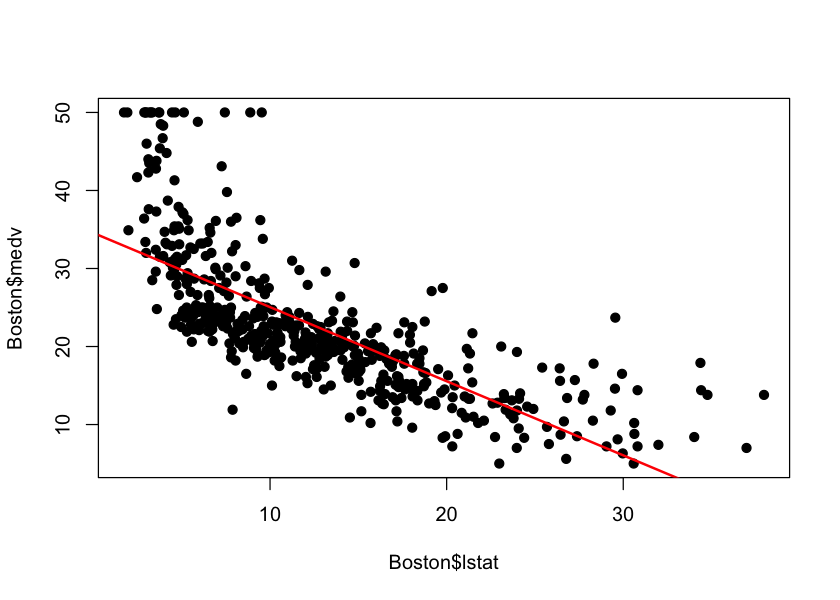

In [41]:
set_plot_defaults()
# Now your plots will work normally
plot(Boston$lstat, Boston$medv, pch=19)
abline(lm.fit, col="red", lw=2)

,fit,lwr,upr
1,29.80359,29.00741,30.59978
2,25.05335,24.47413,25.63256
3,20.30310,19.73159,20.87461


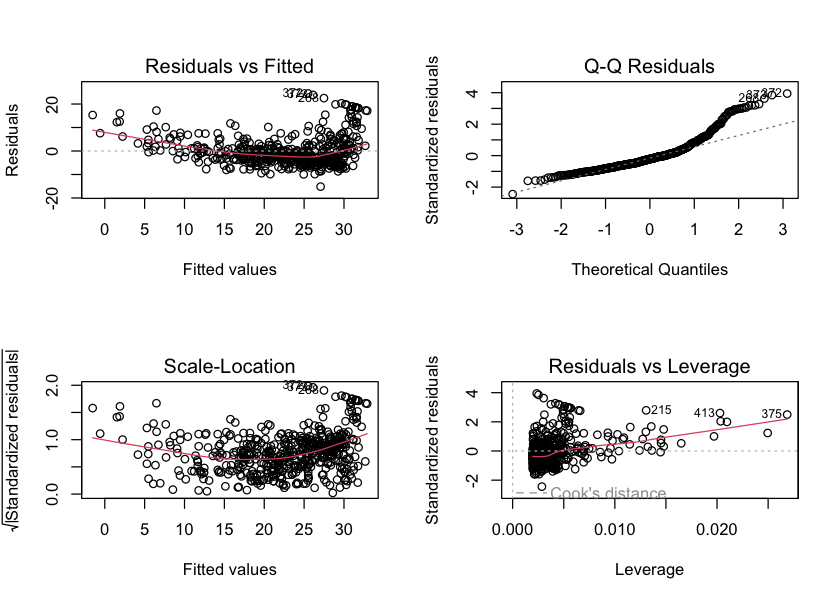

In [42]:
set_plot_defaults()
par(mfrow=c(2,2))
plot(lm.fit) # see the diagnostic plots
predict(lm.fit, data.frame(lstat=c(5,10,15)), interval = "confidence") # predict for three new neighborhoods including confints

375 
375

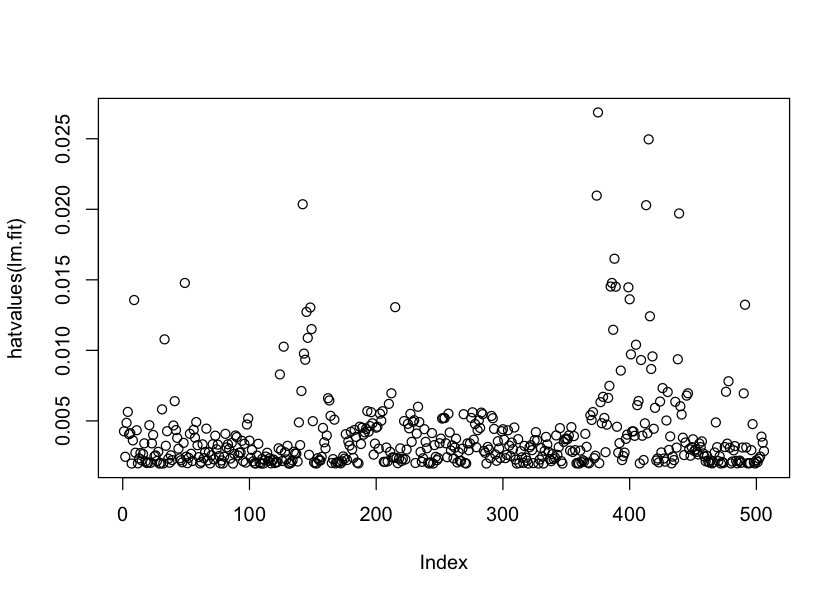

In [43]:
set_plot_defaults()
plot(hatvalues(lm.fit)) # Leverage statistics can be computed for our predictors with hatvalues()
which.max(hatvalues(lm.fit)) # find the observation with the largest leverage

Further questions and tasks:

1. Construct a multiple linear regression model. Start with a full model that deals with all the independent variables. Compare it with the simple model above. Show at least two meaningful ways to compare models of different sizes. Did you improve the simple model?
2. Propose a linear regression model of the right size. Focus on simple approaches, more advanced methods (shrinkage, etc.) will be practiced during the next lab.

In [44]:
# Fit a full model with all predictors
lm.fit.full <- lm(medv ~ ., data = Boston)
summary(lm.fit.full)


Call:
lm(formula = medv ~ ., data = Boston)

Residuals:
    Min      1Q  Median      3Q     Max 
-15.595  -2.730  -0.518   1.777  26.199 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  3.646e+01  5.103e+00   7.144 3.28e-12 ***
crim        -1.080e-01  3.286e-02  -3.287 0.001087 ** 
zn           4.642e-02  1.373e-02   3.382 0.000778 ***
indus        2.056e-02  6.150e-02   0.334 0.738288    
chas         2.687e+00  8.616e-01   3.118 0.001925 ** 
nox         -1.777e+01  3.820e+00  -4.651 4.25e-06 ***
rm           3.810e+00  4.179e-01   9.116  < 2e-16 ***
age          6.922e-04  1.321e-02   0.052 0.958229    
dis         -1.476e+00  1.995e-01  -7.398 6.01e-13 ***
rad          3.060e-01  6.635e-02   4.613 5.07e-06 ***
tax         -1.233e-02  3.760e-03  -3.280 0.001112 ** 
ptratio     -9.527e-01  1.308e-01  -7.283 1.31e-12 ***
black        9.312e-03  2.686e-03   3.467 0.000573 ***
lstat       -5.248e-01  5.072e-02 -10.347  < 2e-16 ***
---
Signif. codes:  0

In [45]:
# Compare nested models statistically
anova(lm.fit, lm.fit.full)

,Res.Df,RSS,Df,Sum of Sq,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,504,19472.38,NA,NA,NA,NA
2,492,11078.78,12,8393.597,31.06275,6.824831e-53


ANSWER 1
the models RSS did improve significantly, however the F value remains quite high, another value which can help determine whether the model improved is R^2

In [46]:
summary(lm.fit)$r.squared
summary(lm.fit.full)$r.squared

[1] 0.5441463

[1] 0.7406427

In [ ]:
We can see that the R^2 value did improve from 0.54 to 0.74, however the F value remains quite high, indicating that the model is still not a great fit.

ANSWER 2
We can try forward or backward selection of parameters and select the model that has the best performace according of model scoring parameter such as R^2

In [47]:
lm.backward <- step(lm.fit.full, direction = "backward")
summary(lm.backward)

Start:  AIC=1589.64
medv ~ crim + zn + indus + chas + nox + rm + age + dis + rad + 
    tax + ptratio + black + lstat

          Df Sum of Sq   RSS    AIC
- age      1      0.06 11079 1587.7
- indus    1      2.52 11081 1587.8
<none>                 11079 1589.6
- chas     1    218.97 11298 1597.5
- tax      1    242.26 11321 1598.6
- crim     1    243.22 11322 1598.6
- zn       1    257.49 11336 1599.3
- black    1    270.63 11349 1599.8
- rad      1    479.15 11558 1609.1
- nox      1    487.16 11566 1609.4
- ptratio  1   1194.23 12273 1639.4
- dis      1   1232.41 12311 1641.0
- rm       1   1871.32 12950 1666.6
- lstat    1   2410.84 13490 1687.3

Step:  AIC=1587.65
medv ~ crim + zn + indus + chas + nox + rm + dis + rad + tax + 
    ptratio + black + lstat

          Df Sum of Sq   RSS    AIC
- indus    1      2.52 11081 1585.8
<none>                 11079 1587.7
- chas     1    219.91 11299 1595.6
- tax      1    242.24 11321 1596.6
- crim     1    243.20 11322 1596.6
- zn       1


Call:
lm(formula = medv ~ crim + zn + chas + nox + rm + dis + rad + 
    tax + ptratio + black + lstat, data = Boston)

Residuals:
     Min       1Q   Median       3Q      Max 
-15.5984  -2.7386  -0.5046   1.7273  26.2373 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  36.341145   5.067492   7.171 2.73e-12 ***
crim         -0.108413   0.032779  -3.307 0.001010 ** 
zn            0.045845   0.013523   3.390 0.000754 ***
chas          2.718716   0.854240   3.183 0.001551 ** 
nox         -17.376023   3.535243  -4.915 1.21e-06 ***
rm            3.801579   0.406316   9.356  < 2e-16 ***
dis          -1.492711   0.185731  -8.037 6.84e-15 ***
rad           0.299608   0.063402   4.726 3.00e-06 ***
tax          -0.011778   0.003372  -3.493 0.000521 ***
ptratio      -0.946525   0.129066  -7.334 9.24e-13 ***
black         0.009291   0.002674   3.475 0.000557 ***
lstat        -0.522553   0.047424 -11.019  < 2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*